# Riboflavin Image Composition Analysis via Parameterization

### Packages

In [2]:
!pip install opencv-python-headless numpy scipy scikit-image pandas matplotlib seaborn scikit-learn tqdm plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 17.4 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 16.4 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 17.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 16.5 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [seaborn]0/11 [seaborn]mage]-headless]


### Visualization (Features)

Deep searching for images in absolute path: /workspace/Riboflavin_NAOH_Water_Dilution
Found 4 matching concentration folders out of ['1', '6', '12.5', '25'].
Starting deep feature extraction loop...

PROCESSING SAMPLE FROM DEEP FOLDER: 1
Full Path: .../1/Capture_1000.bmp


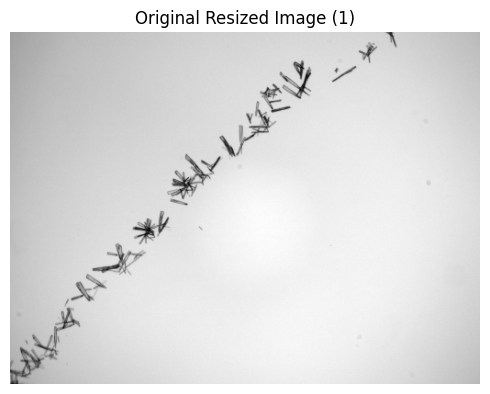

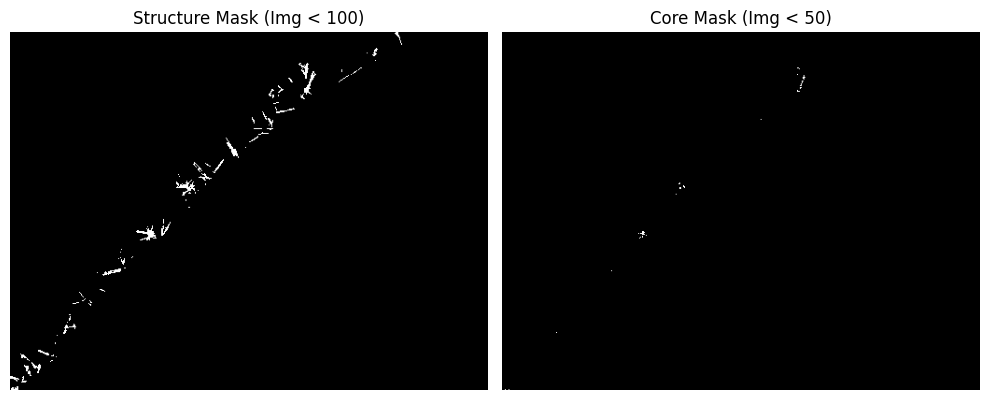

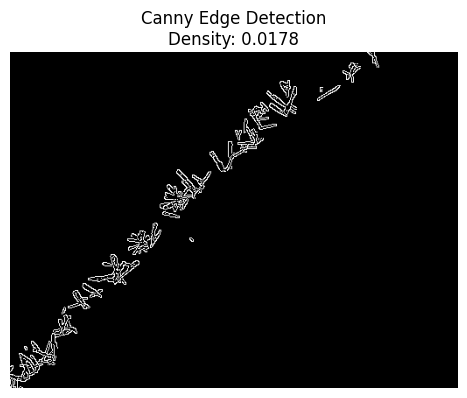

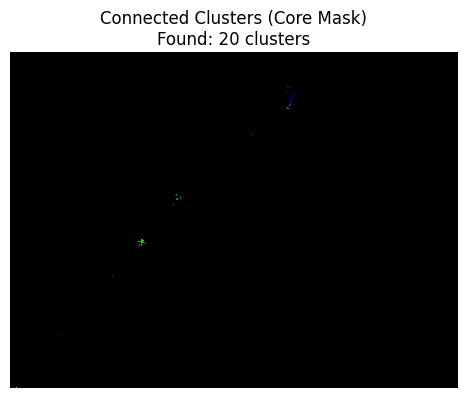

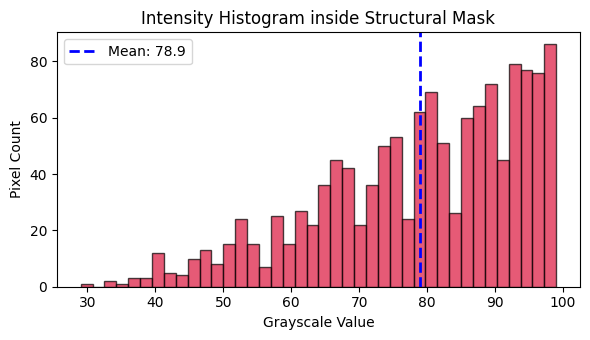

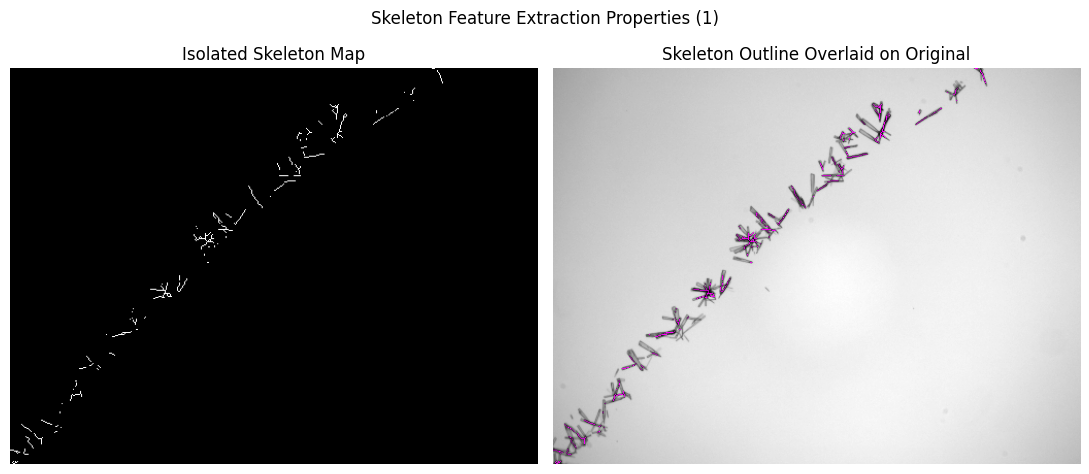

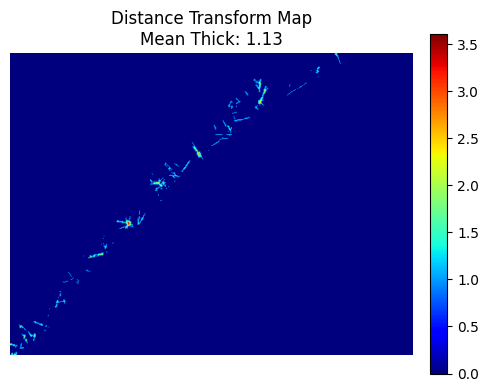

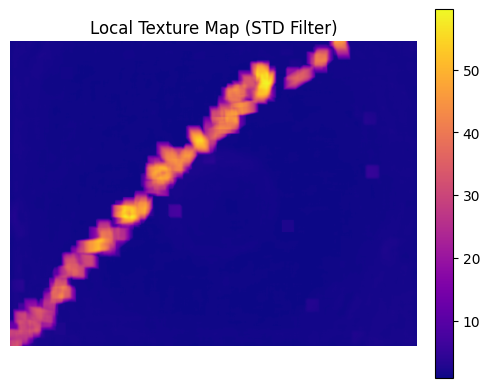

/tmp/ipykernel_210/3733232696.py:253: RuntimeWarning: divide by zero encountered in log
  coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)
/tmp/ipykernel_210/3733232696.py:256: RuntimeWarning: divide by zero encountered in log
  plt.plot(np.log(sizes), np.log(counts), 'ro', label='Data')


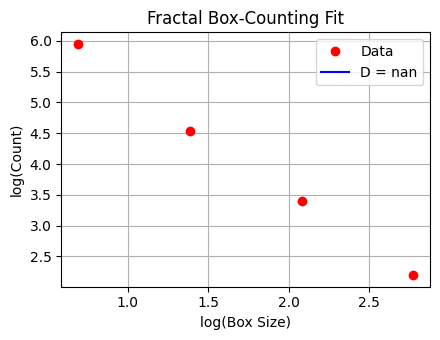

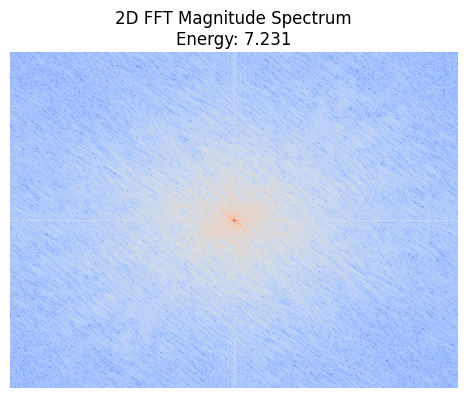

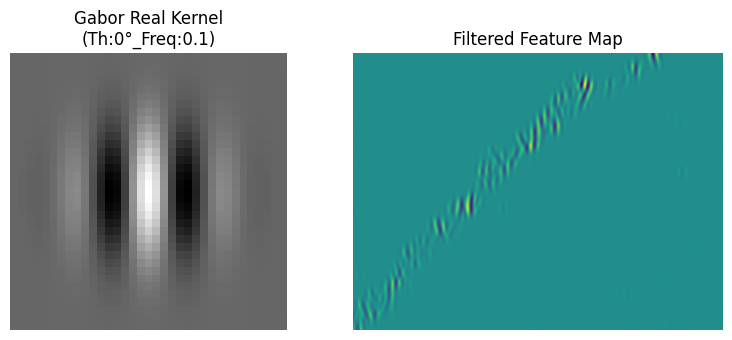

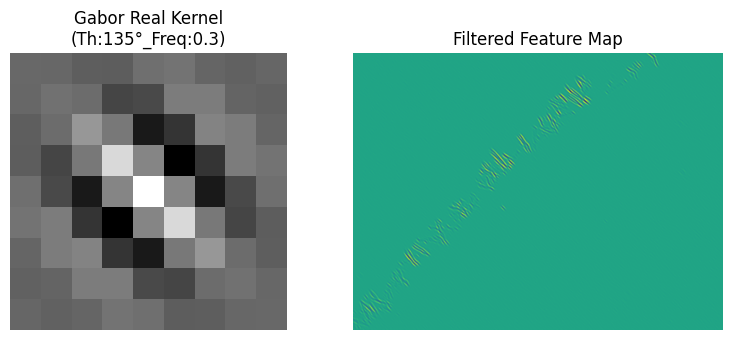


PROCESSING SAMPLE FROM DEEP FOLDER: 12.5
Full Path: .../12.5/Capture_1.bmp


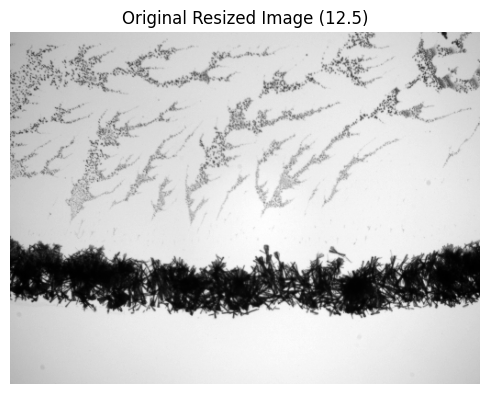

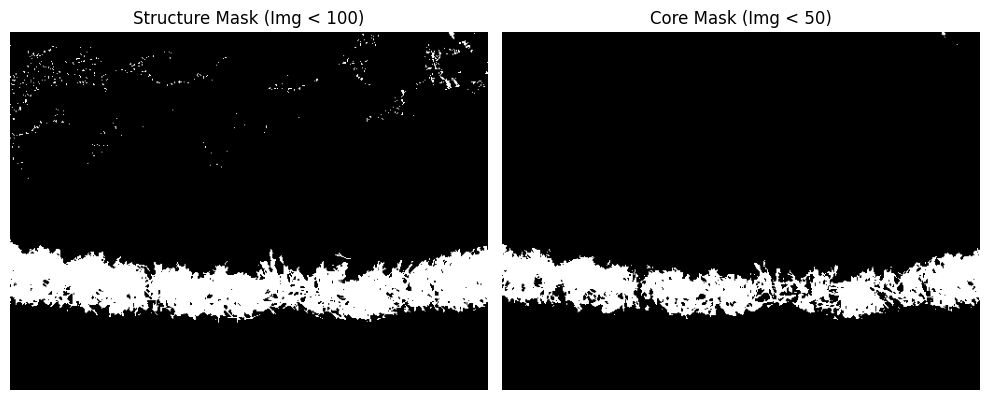

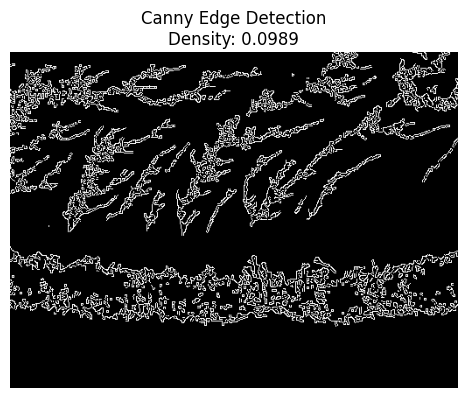

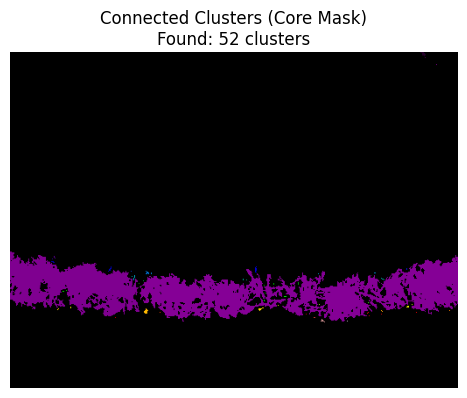

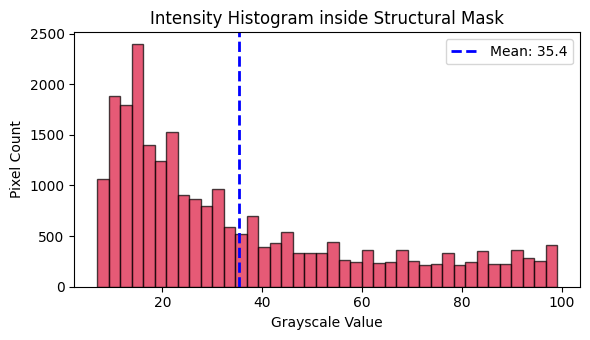

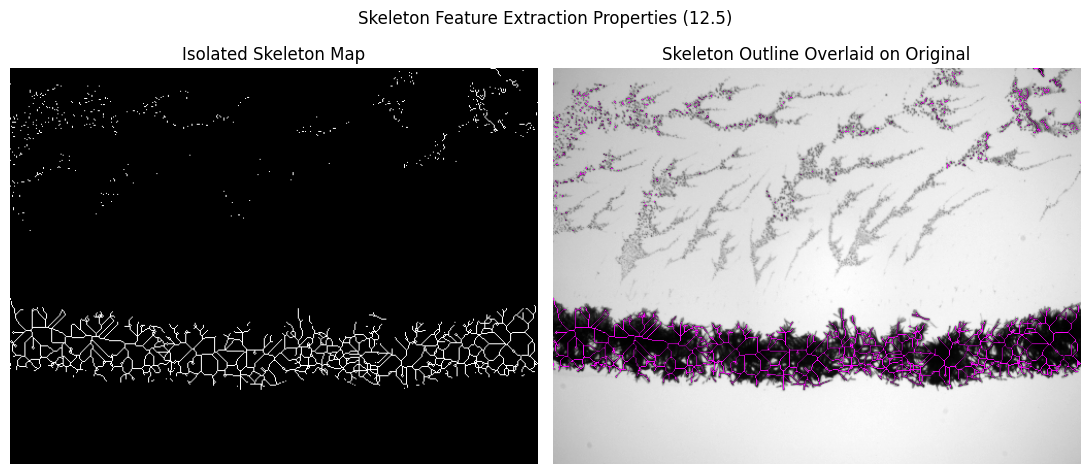

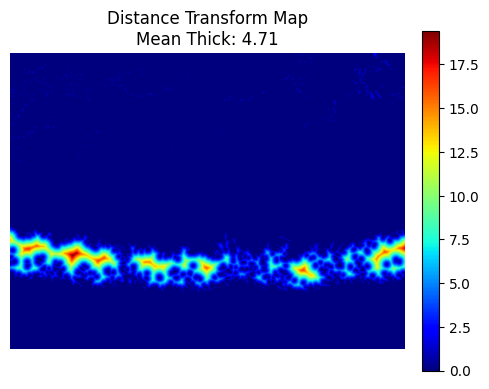

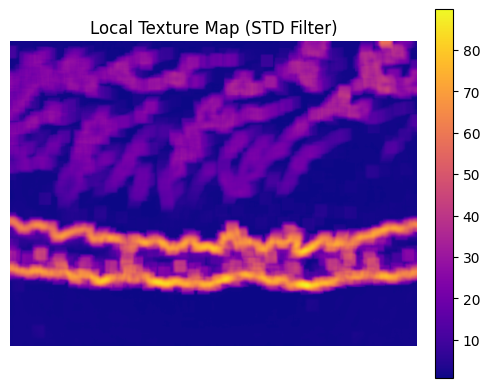

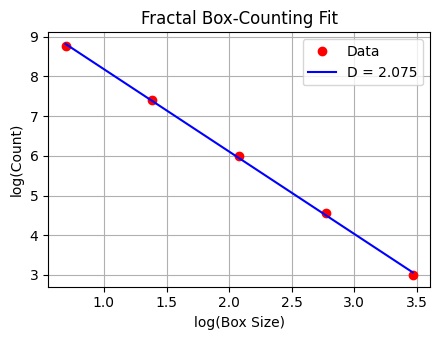

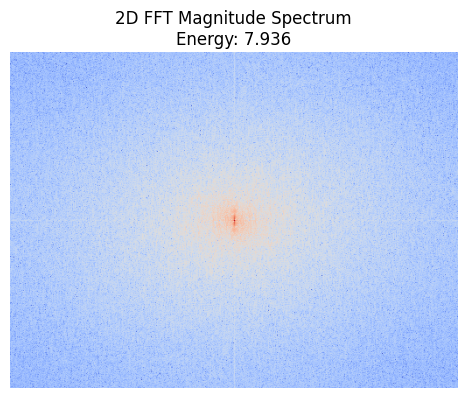

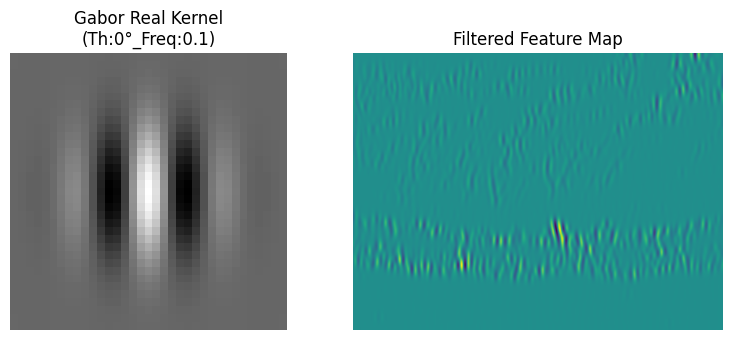

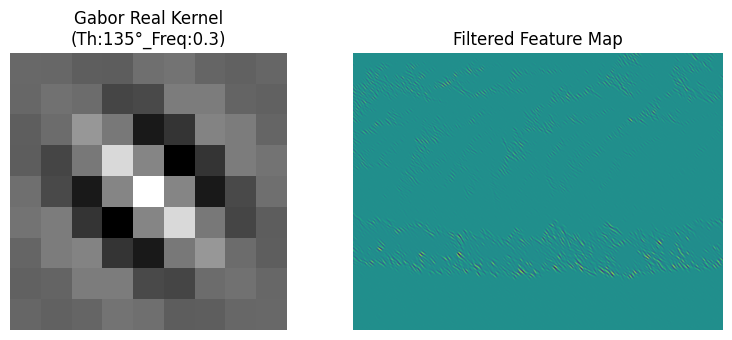


PROCESSING SAMPLE FROM DEEP FOLDER: 25
Full Path: .../25/Capture_1.bmp


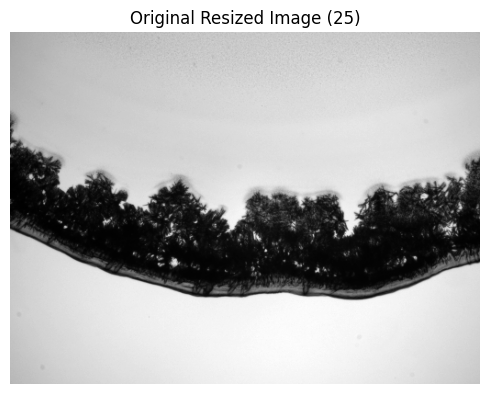

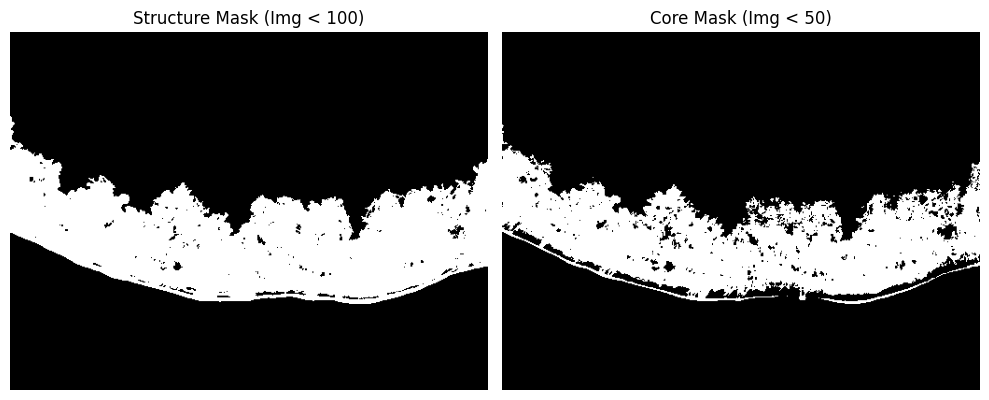

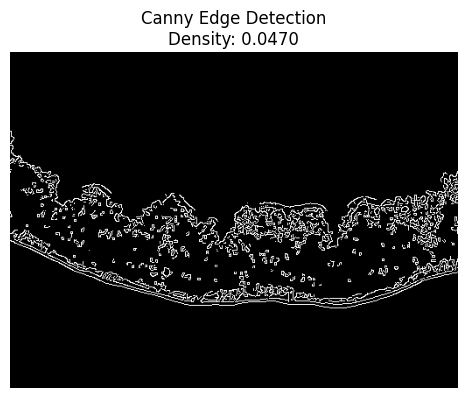

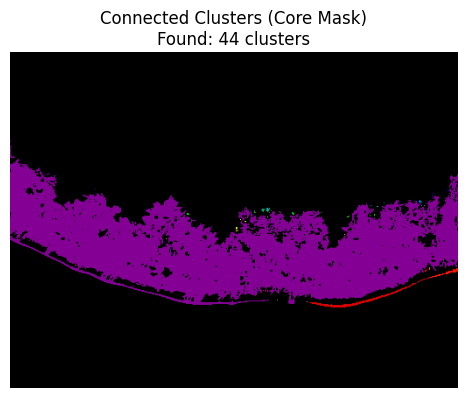

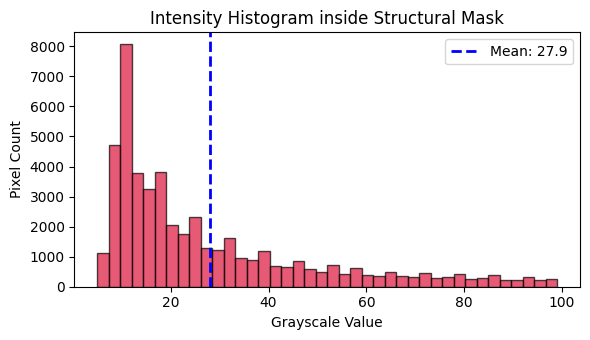

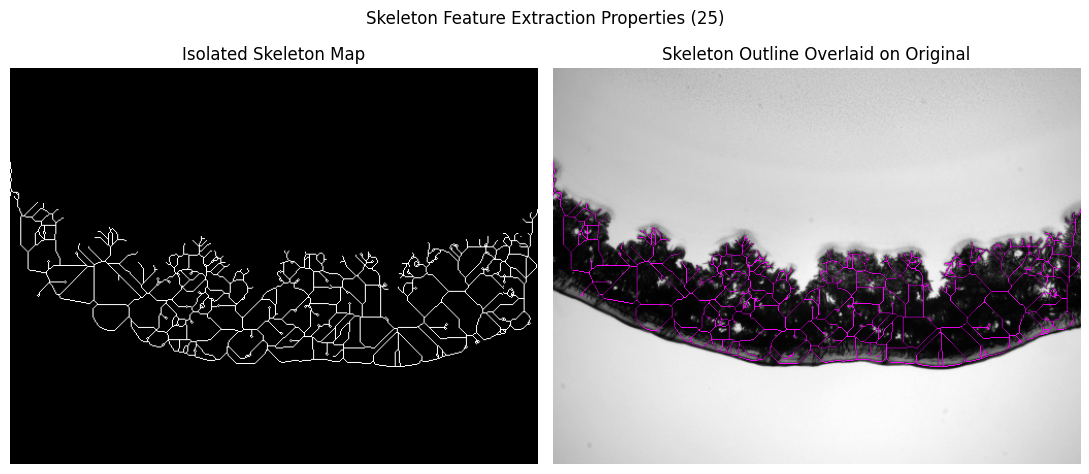

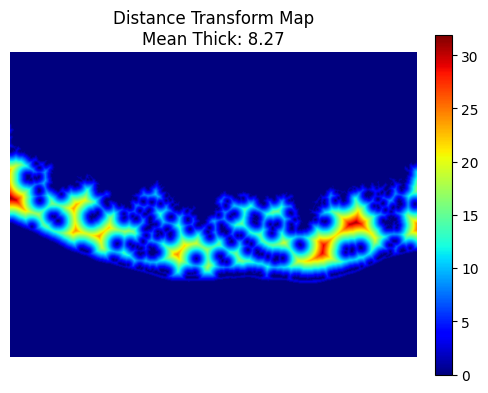

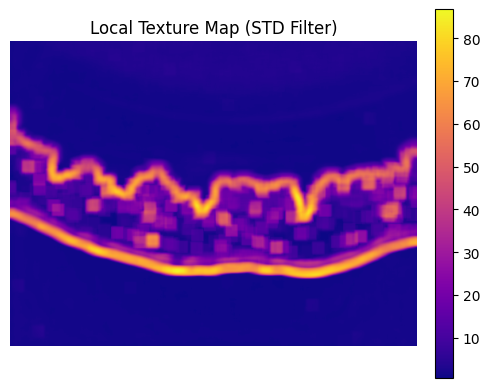

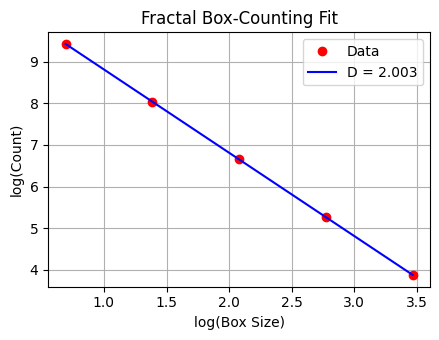

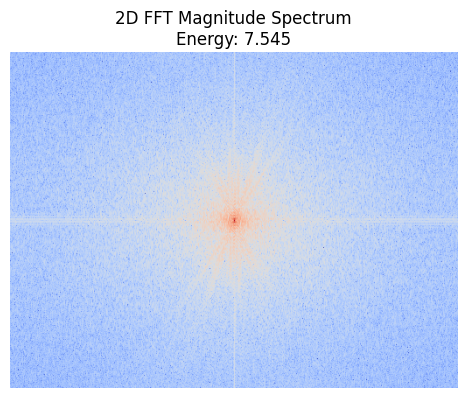

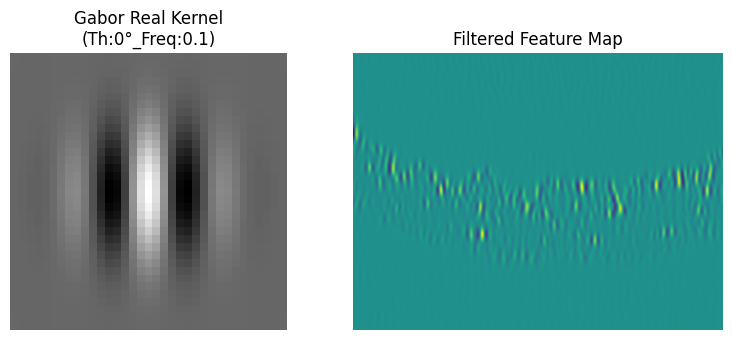

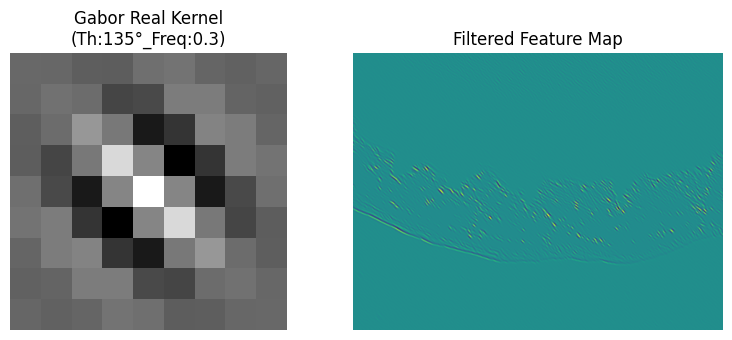


PROCESSING SAMPLE FROM DEEP FOLDER: 6
Full Path: .../6/Capture_1.bmp


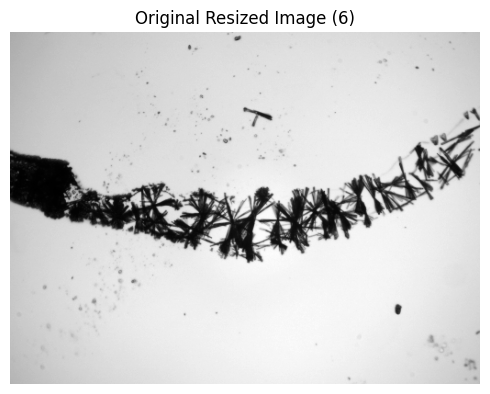

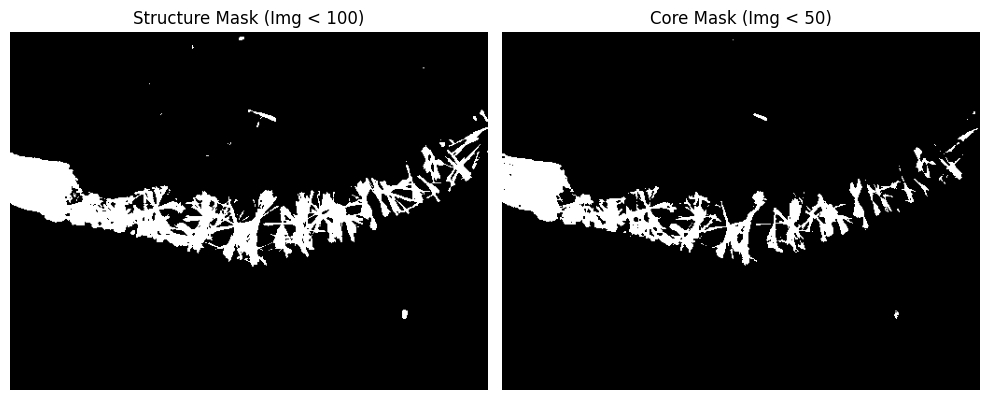

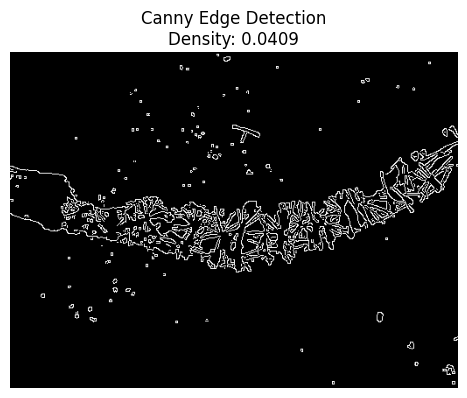

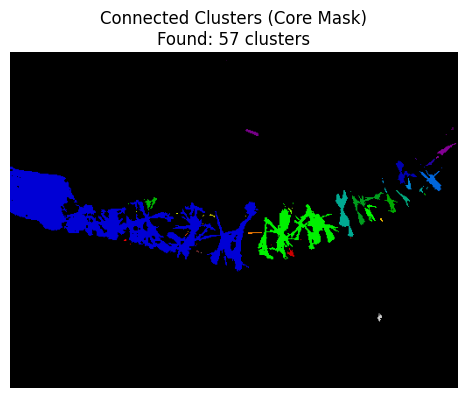

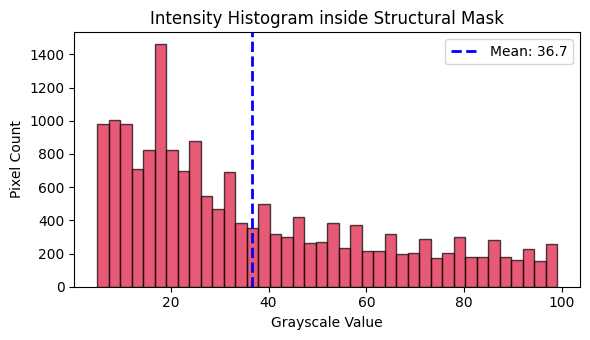

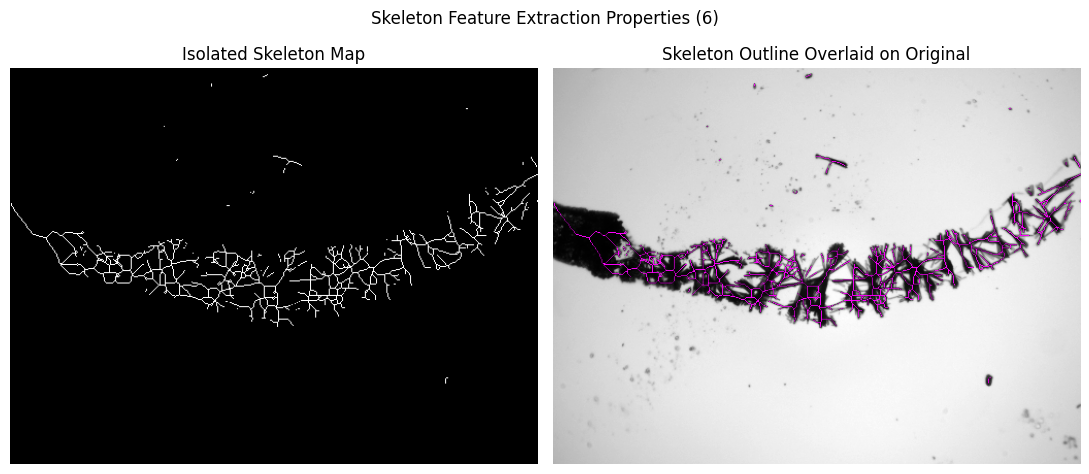

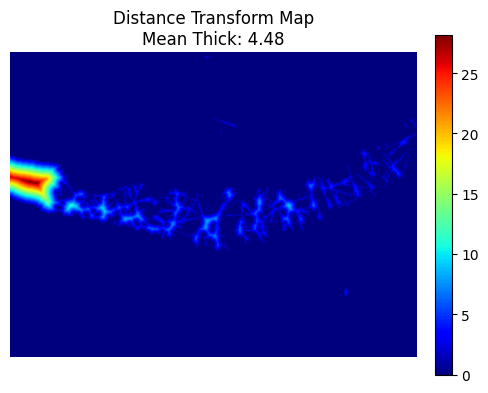

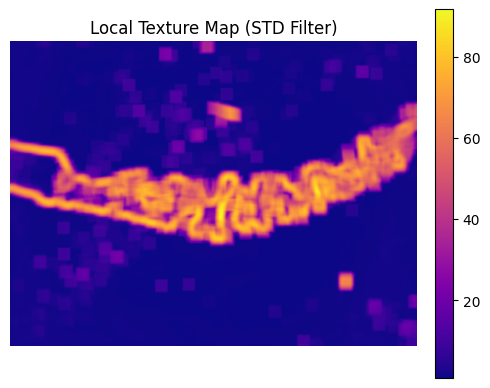

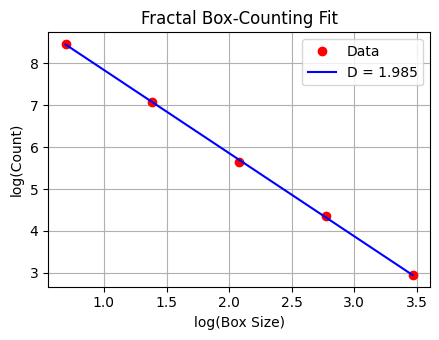

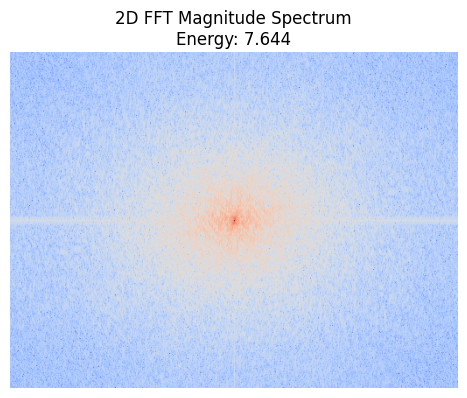

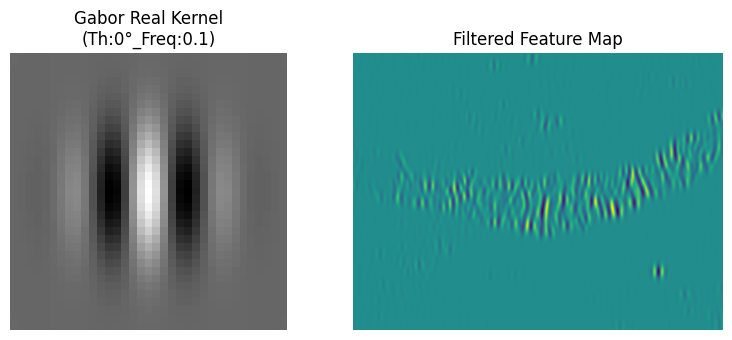

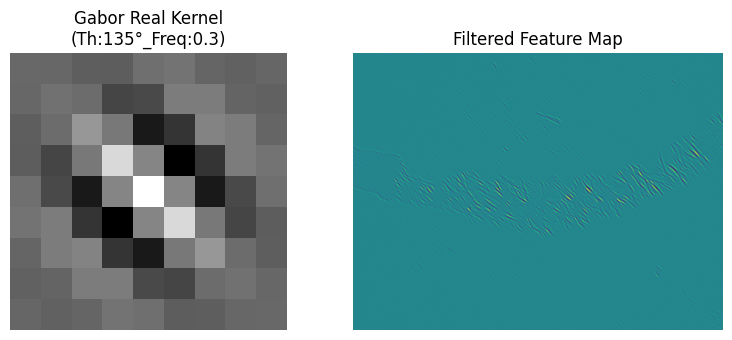


Processing complete! Evaluation windows displayed.


In [4]:
# =========================================================
# MAGIC COMMAND FOR JUPYTER
# =========================================================
%matplotlib inline

import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve, distance_transform_edt, generic_filter
from scipy.stats import kurtosis, skew
from skimage import measure
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import gabor_kernel
from skimage.morphology import skeletonize

# =========================================================
# 1. MAP TARGET SUBFOLDERS FROM PRODUCTION SOURCE
# =========================================================
base_path = Path("./Riboflavin_NAOH_Water_Dilution").resolve()
TARGET_CONCENTRATIONS = ["1", "6", "12.5", "25"]

print(f"Deep searching for images in absolute path: {base_path}")
if not base_path.exists():
    print("❌ ERROR: The directory './Riboflavin_NAOH_Water_Dilution' does not exist relative to this notebook!")
else:
    all_bmp_files = list(base_path.rglob("*.bmp")) + list(base_path.rglob("*.BMP"))
    
    folder_to_samples = {}
    for file_path in all_bmp_files:
        # Filter out hidden or system files
        if any(part.startswith('.') for part in file_path.parts):
            continue
        
        parent_dir = file_path.parent
        folder_name = parent_dir.name
        
        # Match production logic: only index target folders
        if folder_name in TARGET_CONCENTRATIONS:
            if parent_dir not in folder_to_samples:
                folder_to_samples[parent_dir] = []
            folder_to_samples[parent_dir].append(file_path)

    print(f"Found {len(folder_to_samples)} matching concentration folders out of {TARGET_CONCENTRATIONS}.")
    print("Starting deep feature extraction loop...")
    print("="*60)

# =========================================================
# PARAMETERS
# =========================================================
THRES = 100  
CORE_THRES = 50  

# GABOR KERNELS
gabor_kernels = []
kernel_names = []
for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
    for frequency in [0.1, 0.3]:
        kernel = np.real(gabor_kernel(frequency, theta=theta))
        gabor_kernels.append(kernel)
        kernel_names.append(f"Th:{int(np.degrees(theta))}°_Freq:{frequency}")

results = []

# =========================================================
# EXPLICIT LOOP: ONE IMAGE PER DEEP CONCENTRATION FOLDER
# =========================================================
for folder_path, files in folder_to_samples.items():
    label = folder_path.name  
    target_file_path = files[0]
    filename = target_file_path.name
    
    print("\n" + "="*60)
    print(f"PROCESSING SAMPLE FROM DEEP FOLDER: {label}")
    print(f"Full Path: .../{target_file_path.relative_to(base_path)}")
    print("="*60)

    # Read image
    img = cv2.imread(str(target_file_path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"❌ Error loading image: {filename}. Skipping.")
        continue
        
    img = cv2.resize(img, (0, 0), fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)

    # -----------------------------------------------------
    # VISUALIZATION: Original Grayscale Image
    # -----------------------------------------------------
    plt.figure(figsize=(5, 4))
    plt.imshow(img, cmap='gray')
    plt.title(f"Original Resized Image ({label})")
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    # =========================
    # THRESHOLDING
    # =========================
    imgLow = img < THRES  
    imgHigh = img < CORE_THRES  

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(imgLow, cmap='gray')
    axes[0].set_title(f"Structure Mask (Img < {THRES})")
    axes[1].imshow(imgHigh, cmap='gray')
    axes[1].set_title(f"Core Mask (Img < {CORE_THRES})")
    for ax in axes: ax.axis('off')
    plt.tight_layout()
    plt.show()

    # =========================
    # BASIC AREA FEATURES
    # =========================
    total_pixels = img.size  
    area_fraction = np.sum(imgLow) / total_pixels  

    # =========================
    # EDGE FEATURES
    # =========================
    edges = cv2.Canny(img, 50, 150)
    edge_density = np.sum(edges > 0) / total_pixels

    plt.figure(figsize=(5, 4))
    plt.imshow(edges, cmap='gray')
    plt.title(f"Canny Edge Detection\nDensity: {edge_density:.4f}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    # =========================
    # CONNECTED COMPONENTS
    # =========================
    labels = measure.label(imgHigh)
    props = measure.regionprops(labels)
    num_clusters = len(props)
    areas = [p.area for p in props] if props else [0]
    mean_cluster_area = np.mean(areas)
    ecc = [p.eccentricity for p in props] if props else [0]
    mean_eccentricity = np.mean(ecc)

    plt.figure(figsize=(5, 4))
    plt.imshow(labels, cmap='nipy_spectral')
    plt.title(f"Connected Clusters (Core Mask)\nFound: {num_clusters} clusters")
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    # =========================
    # INTENSITY STATISTICS
    # =========================
    pixels_crystal = img[img < THRES]
    mean_intensity = np.mean(pixels_crystal) if len(pixels_crystal) else 0
    std_intensity = np.std(pixels_crystal) if len(pixels_crystal) else 0
    skew_intensity = skew(pixels_crystal) if len(pixels_crystal) else 0
    kurt_intensity = kurtosis(pixels_crystal) if len(pixels_crystal) else 0

    plt.figure(figsize=(6, 3.5))
    plt.hist(pixels_crystal.ravel(), bins=40, color='crimson', alpha=0.7, edgecolor='black')
    plt.axvline(mean_intensity, color='blue', linestyle='dashed', linewidth=2, label=f'Mean: {mean_intensity:.1f}')
    plt.title("Intensity Histogram inside Structural Mask")
    plt.xlabel("Grayscale Value")
    plt.ylabel("Pixel Count")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # =========================
    # SKELETON FEATURES
    # =========================
    skel = skeletonize(imgLow)
    skeleton_length = np.sum(skel)
    skel_uint8 = skel.astype(np.uint8)

    kernel_3x3 = np.array([[1, 1, 1],
                           [1, 0, 1],
                           [1, 1, 1]], dtype=np.uint8)
    
    neighbor_count = convolve(skel_uint8, kernel_3x3, mode='constant', cval=0)
    skeleton_neighbors = neighbor_count * skel_uint8

    num_endpoints = np.sum(skeleton_neighbors == 1)
    num_branches = np.sum(skeleton_neighbors >= 3)
    
    # Create a masked overlay array for visual clarity (0 where skeleton isn't present)
    skel_overlay = np.ma.masked_where(skel == 0, skel)

    # -----------------------------------------------------
    # VISUALIZATION: Skeleton Detected Outline Overlaid
    # -----------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    
    # Left: Bare isolated skeleton path
    axes[0].imshow(skel, cmap='gray')
    axes[0].set_title("Isolated Skeleton Map")
    axes[0].axis('off')
    
    # Right: Skeleton drawn as an illuminated line over the crystal image
    axes[1].imshow(img, cmap='gray')
    axes[1].imshow(skel_overlay, cmap='spring')  # Magenta/orange neon tone
    axes[1].set_title("Skeleton Outline Overlaid on Original")
    axes[1].axis('off')
    
    plt.suptitle(f"Skeleton Feature Extraction Properties ({label})")
    plt.tight_layout()
    plt.show()

    # =========================
    # DISTANCE TRANSFORM
    # =========================
    dist_map = distance_transform_edt(imgLow)
    mean_thickness = np.mean(dist_map[imgLow]) if np.sum(imgLow) > 0 else 0
    max_thickness = np.max(dist_map) if np.sum(imgLow) > 0 else 0

    plt.figure(figsize=(5, 4))
    plt.imshow(dist_map, cmap='jet')
    plt.colorbar(fraction=0.046, pad=0.04)
    plt.title(f"Distance Transform Map\nMean Thick: {mean_thickness:.2f}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    # =========================
    # TEXTURE (GLCM) & LOCAL STD
    # =========================
    glcm = graycomatrix(img, [1], [0], symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]

    local_std = generic_filter(img.astype(float), np.std, size=15)
    mean_local_std = np.mean(local_std)
    std_local_std = np.std(local_std)

    plt.figure(figsize=(5, 4))
    plt.imshow(local_std, cmap='plasma')
    plt.colorbar(fraction=0.046, pad=0.04)
    plt.title("Local Texture Map (STD Filter)")
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    # =========================
    # FRACTAL DIMENSION
    # =========================
    def fractal_dimension_vis(Z):
        Z = Z < THRES  
        sizes = np.array([2, 4, 8, 16, 32])
        counts = []
        for size in sizes:
            resized = cv2.resize(Z.astype(np.uint8), (Z.shape[1]//size, Z.shape[0]//size))
            counts.append(np.sum(resized > 0))
        coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)
        
        plt.figure(figsize=(4.5, 3.5))
        plt.plot(np.log(sizes), np.log(counts), 'ro', label='Data')
        plt.plot(np.log(sizes), np.polyval(coeffs, np.log(sizes)), 'b-', label=f'D = {-coeffs[0]:.3f}')
        plt.xlabel('log(Box Size)')
        plt.ylabel('log(Count)')
        plt.title('Fractal Box-Counting Fit')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()
        return -coeffs[0]

    fractal_dim = fractal_dimension_vis(img)

    # =========================
    # FFT FEATURES
    # =========================
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    magnitude = np.log(np.abs(fshift) + 1)
    fft_energy = np.mean(magnitude)

    plt.figure(figsize=(5, 4))
    plt.imshow(magnitude, cmap='coolwarm')
    plt.title(f"2D FFT Magnitude Spectrum\nEnergy: {fft_energy:.3f}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    # =========================
    # GABOR TEXTURE FEATURES
    # =========================
    gabor_features = []
    vis_indices = [0, len(gabor_kernels)-1] 
    
    for i, kernel in enumerate(gabor_kernels):
        filtered = convolve(img.astype(float), kernel, mode='reflect')
        
        gabor_features.append(np.mean(filtered))
        gabor_features.append(np.std(filtered))
        gabor_features.append(np.mean(filtered ** 2))
        gabor_features.append(np.max(filtered))
        gabor_features.append(skew(filtered.ravel()))
        
        if i in vis_indices:
            fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
            axes[0].imshow(kernel, cmap='gray')
            axes[0].set_title(f"Gabor Real Kernel\n({kernel_names[i]})")
            axes[1].imshow(filtered, cmap='viridis')
            axes[1].set_title("Filtered Feature Map")
            for ax in axes: ax.axis('off')
            plt.tight_layout()
            plt.show()

    # =========================
    # STORE FEATURES
    # =========================
    feature_vector = [
        filename, label, area_fraction, edge_density, num_clusters,
        mean_cluster_area, mean_eccentricity, mean_intensity, std_intensity,
        skew_intensity, kurt_intensity, skeleton_length, num_branches,
        num_endpoints, mean_thickness, max_thickness, contrast, energy,
        correlation, mean_local_std, std_local_std, fractal_dim, fft_energy
    ]
    feature_vector.extend(gabor_features)
    results.append(feature_vector)

print("\nProcessing complete! Evaluation windows displayed.")

## Feature Extraction

In [6]:
# =========================
# IMPORT LIBRARIES
# =========================

import os  # for file and folder operations (listing images, paths)
import cv2  # OpenCV for image reading and processing
import numpy as np  # numerical operations (arrays, math)
import pandas as pd  # storing results in table form (CSV output)

from skimage import measure  # connected components and region properties
from skimage.morphology import skeletonize  # skeleton extraction
from skimage.feature import graycomatrix, graycoprops  # texture (GLCM)

from scipy.stats import skew, kurtosis  # statistical descriptors
from scipy.ndimage import generic_filter, distance_transform_edt  # local filters and distances

# gabor
from skimage.filters import gabor_kernel
from scipy.ndimage import convolve

from tqdm import tqdm  # progress bar library

# =========================
# PARAMETERS
# =========================

THRES = 100  # threshold for detecting general riboflavin structure (pixels BELOW this value)
CORE_THRES = 50 # threshold for detecting darker structures

# =========================
# GABOR FILTER PARAMETERS
# =========================
gabor_kernels = []
for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
    for frequency in [0.1, 0.3]:
        kernel = np.real(gabor_kernel(frequency, theta=theta))
        gabor_kernels.append(kernel)


# =========================
# INPUT FOLDER (Updated for Clean Structure)
# =========================

image_folder = r"./Riboflavin_NAOH_Water_Dilution"


# =========================
# STORAGE FOR RESULTS
# =========================

results = []  # list to collect feature vectors for all images


# =========================
# LOOP THROUGH IMAGES
# =========================

# Target concentrations to extract (must match your folder names exactly)
TARGET_CONCENTRATIONS = ["1", "6", "12.5", "25", "50", "100"]

for root, dirs, files in os.walk(image_folder):  # loop through all files in folder
    folder_name = os.path.basename(root)  # This captures the immediate parent folder name
    
    # Direct match check: Skip the folder if it isn't one of our targets
    if folder_name not in TARGET_CONCENTRATIONS:
        continue
        
    label = folder_name  # The folder name itself acts as our concentration label

    # Filter for .bmp files first so tqdm has an accurate total count for the progress bar
    bmp_files = [f for f in files if f.lower().endswith(".bmp")]
    if not bmp_files:
        continue

    # Track file processing progress per concentration directory using tqdm
    for filename in tqdm(bmp_files, desc=f"Processing folder: {label}"):
        
        path = os.path.join(root, filename)  # create full file path
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)  # read image as grayscale
        
        if img is None:
            continue
    
        # reduce image size (400% faster)
        img = cv2.resize(img, (0, 0), fx = 0.5, fy = 0.5, interpolation=cv2.INTER_AREA)

        # =========================
        # THRESHOLDING
        # =========================

        imgLow = img < THRES  # binary mask: all riboflavin structures
        imgHigh = img < CORE_THRES  # binary mask: only brightest regions


        # =========================
        # BASIC AREA FEATURES
        # =========================

        total_pixels = img.size  # total number of pixels in image

        area_fraction = np.sum(imgLow) / total_pixels  # fraction of image covered by structure


        # =========================
        # EDGE FEATURES
        # =========================

        edges = cv2.Canny(img, 50, 150)  # detect edges using Canny algorithm

        edge_density = np.sum(edges > 0) / total_pixels  # fraction of pixels that are edges


        # =========================
        # CONNECTED COMPONENTS
        # =========================

        labels = measure.label(imgHigh)  # label each connected bright region

        props = measure.regionprops(labels)  # extract properties of each region

        num_clusters = len(props)  # number of bright clusters

        areas = [p.area for p in props] if props else [0]  # list of cluster areas (avoid empty)

        mean_cluster_area = np.mean(areas)  # average size of clusters

        ecc = [p.eccentricity for p in props] if props else [0]  # shape elongation of clusters

        mean_eccentricity = np.mean(ecc)  # average elongation


        # =========================
        # INTENSITY STATISTICS
        # =========================

        pixels_crystal = img[img < THRES]  # select pixels belonging to structure

        mean_intensity = np.mean(pixels_crystal) if len(pixels_crystal) else 0  # average brightness

        std_intensity = np.std(pixels_crystal) if len(pixels_crystal) else 0  # intensity variation

        skew_intensity = skew(pixels_crystal) if len(pixels_crystal) else 0  # asymmetry

        kurt_intensity = kurtosis(pixels_crystal) if len(pixels_crystal) else 0  # peakedness


        # =========================
        # SKELETON FEATURES
        # =========================

        skel = skeletonize(imgLow)  # reduce structure to 1-pixel-wide skeleton

        skeleton_length = np.sum(skel)  # total length of skeleton

        skel_uint8 = skel.astype(np.uint8)

        kernel_3x3 = np.array([[1, 1, 1],
                               [1, 0, 1],
                               [1, 1, 1]], dtype=np.uint8)
        
        neighbor_count = convolve(skel_uint8, kernel_3x3, mode='constant', cval=0)

        skeleton_neighbors = neighbor_count * skel_uint8

        num_endpoints = np.sum(skeleton_neighbors == 1)

        num_branches = np.sum(skeleton_neighbors >= 3)
        
        # =========================
        # DISTANCE TRANSFORM
        # =========================

        dist_map = distance_transform_edt(imgLow)  # distance to nearest background pixel

        mean_thickness = np.mean(dist_map[imgLow]) if np.sum(imgLow) > 0 else 0  # average thickness
        max_thickness = np.max(dist_map) if np.sum(imgLow) > 0 else 0  # thickest region


        # =========================
        # TEXTURE (GLCM)
        # =========================

        glcm = graycomatrix(img, [1], [0], symmetric=True, normed=True)  # co-occurrence matrix

        contrast = graycoprops(glcm, 'contrast')[0, 0]  # texture contrast

        energy = graycoprops(glcm, 'energy')[0, 0]  # uniformity

        correlation = graycoprops(glcm, 'correlation')[0, 0]  # pixel dependency


        # =========================
        # LOCAL TEXTURE (STD FILTER)
        # =========================

        local_std = generic_filter(img.astype(float), np.std, size=15)  # local std in 15x15 window

        mean_local_std = np.mean(local_std)  # average local variation

        std_local_std = np.std(local_std)  # variation of variation


        # =========================
        # FRACTAL DIMENSION
        # =========================

        def fractal_dimension(Z):

            Z = Z < THRES  # convert to binary

            sizes = np.array([2, 4, 8, 16, 32])  # box sizes

            counts = []  # store number of occupied boxes

            for size in sizes:

                resized = cv2.resize(Z.astype(np.uint8), (Z.shape[1]//size, Z.shape[0]//size))  # shrink image

                counts.append(np.sum(resized > 0))  # count non-empty boxes

            coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)  # fit line in log-log space

            return -coeffs[0]  # slope gives fractal dimension

        fractal_dim = fractal_dimension(img)  # compute fractal dimension


        # =========================
        # FFT FEATURES (FREQUENCY DOMAIN)
        # =========================

        f = np.fft.fft2(img)  # compute 2D Fourier transform

        fshift = np.fft.fftshift(f)  # shift zero frequency to center

        magnitude = np.log(np.abs(fshift) + 1)  # magnitude spectrum

        fft_energy = np.mean(magnitude)  # average frequency energy

        # =========================
        # GABOR TEXTURE FEATURES
        # =========================
        gabor_features = []
        for i, kernel in enumerate(gabor_kernels):
            filtered = convolve(img.astype(float), kernel, mode='reflect')
            
            gabor_features.append(np.mean(filtered))
            gabor_features.append(np.std(filtered))
            gabor_features.append(np.mean(filtered ** 2)) # Energy
            gabor_features.append(np.max(filtered))        # Peak response
            gabor_features.append(skew(filtered.ravel()))  # Distribution shape

        # =========================
        # STORE FEATURES
        # =========================

        feature_vector = [
            filename,  # image name
            label,  # concentration (extracted value, e.g., 1, 6.25, 12.5)
            area_fraction,
            edge_density,
            num_clusters,
            mean_cluster_area,
            mean_eccentricity,
            mean_intensity,
            std_intensity,
            skew_intensity,
            kurt_intensity,
            skeleton_length,
            num_branches,
            num_endpoints,
            mean_thickness,
            max_thickness,
            contrast,
            energy,
            correlation,
            mean_local_std,
            std_local_std,
            fractal_dim,
            fft_energy
        ]

        feature_vector.extend(gabor_features)
        results.append(feature_vector)

print("\n Feature extraction on Riboflavin_NAOH_Water_Dilution complete.")

Processing folder: 1:   0%|                                                                 | 0/980 [00:00<?, ?it/s]/tmp/ipykernel_210/412717683.py:221: RuntimeWarning: divide by zero encountered in log
  coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)  # fit line in log-log space
Processing folder: 6: 100%|███████████████████████████████████████████████████████| 888/888 [21:04<00:00,  1.42s/it]


 Feature extraction on Riboflavin_NAOH_Water_Dilution complete.


In [7]:
# =========================
# SAVE RESULTS
# =========================

columns = [  # column names for CSV
    "filename", "label", "area_fraction","edge_density","num_clusters",
    "mean_cluster_area","mean_eccentricity","mean_intensity",
    "std_intensity","skew","kurtosis","skeleton_length","skeleton_branches","skeleton_endpoints",
    "mean_thickness","max_thickness","contrast","energy",
    "correlation","mean_local_std","std_local_std",
    "fractal_dim","fft_energy"
]

for theta in [0, 45, 90, 135]: # Degrees for cleaner names
    for freq in [0.1, 0.3]:
        for stat in ["mean", "std", "energy", "max", "skew"]:
            columns.append(f"gabor_ang{theta}_f{freq}_{stat}")

df = pd.DataFrame(results, columns=columns)  # create DataFrame

df.to_csv("riboflavin_features_NAOH.csv", index=False)  # save to CSV file

print("Results stored in riboflavin_features_NAOH.csv")

Results stored in riboflavin_features_NAOH.csv


## Model Training

In [5]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier # Example model
from sklearn.metrics import classification_report

# 1. LOAD DATA
df = pd.read_csv("riboflavin_features_new.csv")

df = df.replace([np.inf, -np.inf], np.nan)

initial_count = len(df)
df = df.dropna()
final_count = len(df)
if initial_count != final_count:
    print(f"Dropped {initial_count - final_count} images due to NaN/Inf values.")

df['label'] = df['label'].astype(str)

# Map the inconsistent folders to your primary categories
label_map = {
    "6.25": "6.0",
    "6.5" : "6.0",
    "12.5": "12.0",
}

df = df[df['label'] != '.ipynb_checkpoints']
df['label'] = df['label'].replace(label_map)

# 2. SEPARATE FEATURES AND TARGET
X = df.drop(columns=["filename", "label"]) 
y = df["label"]

z_scores = np.abs(stats.zscore(X, nan_policy='omit'))
outlier_idx = np.any(np.abs(z_scores) > 6, axis = 1)
print(f"Dropped {sum(outlier_idx)} data points with z-score > 6.")
filtered_mask = ~outlier_idx

X = X[filtered_mask]
y = y[filtered_mask]

# 3. SPLIT INTO TRAINING AND TESTING SETS
# Usually 80% to train the model, 20% to see if it actually learned
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 4. SCALE THE FEATURES (Crucial!)
# Scaling puts them all on a similar range (usually 0 to 1 or -1 to 1).
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. TRAIN A MODEL
model = RandomForestClassifier(n_estimators=300)
model.fit(X_train_scaled, y_train)

# 6. EVALUATE
predictions = model.predict(X_test_scaled)
print(classification_report(y_test, predictions))

# Generate report as a dictionary instead of a string
report_dict = classification_report(y_test, predictions, output_dict=True)

# Convert to DataFrame
report_df = pd.DataFrame(report_dict).transpose()

# The report includes 'accuracy', 'macro avg', and 'weighted avg' rows.
# We want to sort the concentrations but keep the summary stats at the bottom.
stats_rows = ['accuracy', 'macro avg', 'weighted avg']
concentration_df = report_df.drop(index=stats_rows, errors='ignore')
summary_df = report_df.loc[report_df.index.isin(stats_rows)]

# Sort the concentrations numerically
# We temporarily convert index to float to sort, then back to string
concentration_df.index = concentration_df.index.astype(float)
concentration_df = concentration_df.sort_index()
concentration_df.index = concentration_df.index.astype(str)

# Combine back together
sorted_report = pd.concat([concentration_df, summary_df])

print("\nSorted Classification Report:")
print(sorted_report)

# =========================
# FEATURE IMPORTANCE (SORTED)
# =========================
importances = pd.Series(model.feature_importances_, index=X.columns)
print("\nTop 30 Most Important Features:")
print(importances.sort_values(ascending=False).head(30))

Dropped 295 images due to NaN/Inf values.
Dropped 75 data points with z-score > 6.
              precision    recall  f1-score   support

         1.0       0.95      0.88      0.91       142
       100.0       0.91      0.99      0.95       116
        12.0       0.97      0.97      0.97       178
        25.0       0.88      0.94      0.91       135
        50.0       0.99      0.96      0.97       169
         6.0       0.92      0.87      0.89        82

    accuracy                           0.94       822
   macro avg       0.94      0.93      0.93       822
weighted avg       0.94      0.94      0.94       822


Sorted Classification Report:
              precision    recall  f1-score     support
1.0            0.946970  0.880282  0.912409  142.000000
6.0            0.922078  0.865854  0.893082   82.000000
12.0           0.966292  0.966292  0.966292  178.000000
25.0           0.875862  0.940741  0.907143  135.000000
50.0           0.987805  0.958580  0.972973  169.000000
100.0  

In [6]:
# ==========================================
# REGRESSION MODELING (PREDICTING VALUE)
# ==========================================
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare numerical target
# Regression needs numbers, not strings
y_train_reg = y_train.astype(float)
y_test_reg = y_test.astype(float)

# 2. Train Regressor
reg_model = RandomForestRegressor(n_estimators=300, random_state=3, n_jobs=-1)
reg_model.fit(X_train_scaled, y_train_reg)

# 3. Predict and Evaluate
reg_predictions = reg_model.predict(X_test_scaled)

mae = mean_absolute_error(y_test_reg, reg_predictions)
r2 = r2_score(y_test_reg, reg_predictions)

print("--- REGRESSION RESULTS ---")
print(f"Mean Absolute Error: {mae:.4f} units")
print(f"R² Score: {r2:.4f}")

--- REGRESSION RESULTS ---
Mean Absolute Error: 3.7743 units
R² Score: 0.8997


## Visualizations

In [7]:
import pandas as pd

# 1. Get feature importances from your trained model
# Replace 'model' with your actual trained Random Forest/XGBoost variable
importances = model.feature_importances_
feature_names = X.columns

# 2. Create a DataFrame and sort
feature_importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
top_50_features = feature_importance_df.sort_values(by='importance', ascending=False).head(50)['feature'].values

# 3. Filter your data
X_top_50 = X[top_50_features]
X_top_50_scaled = scaler.fit_transform(X_top_50) # Re-scale based only on these 50

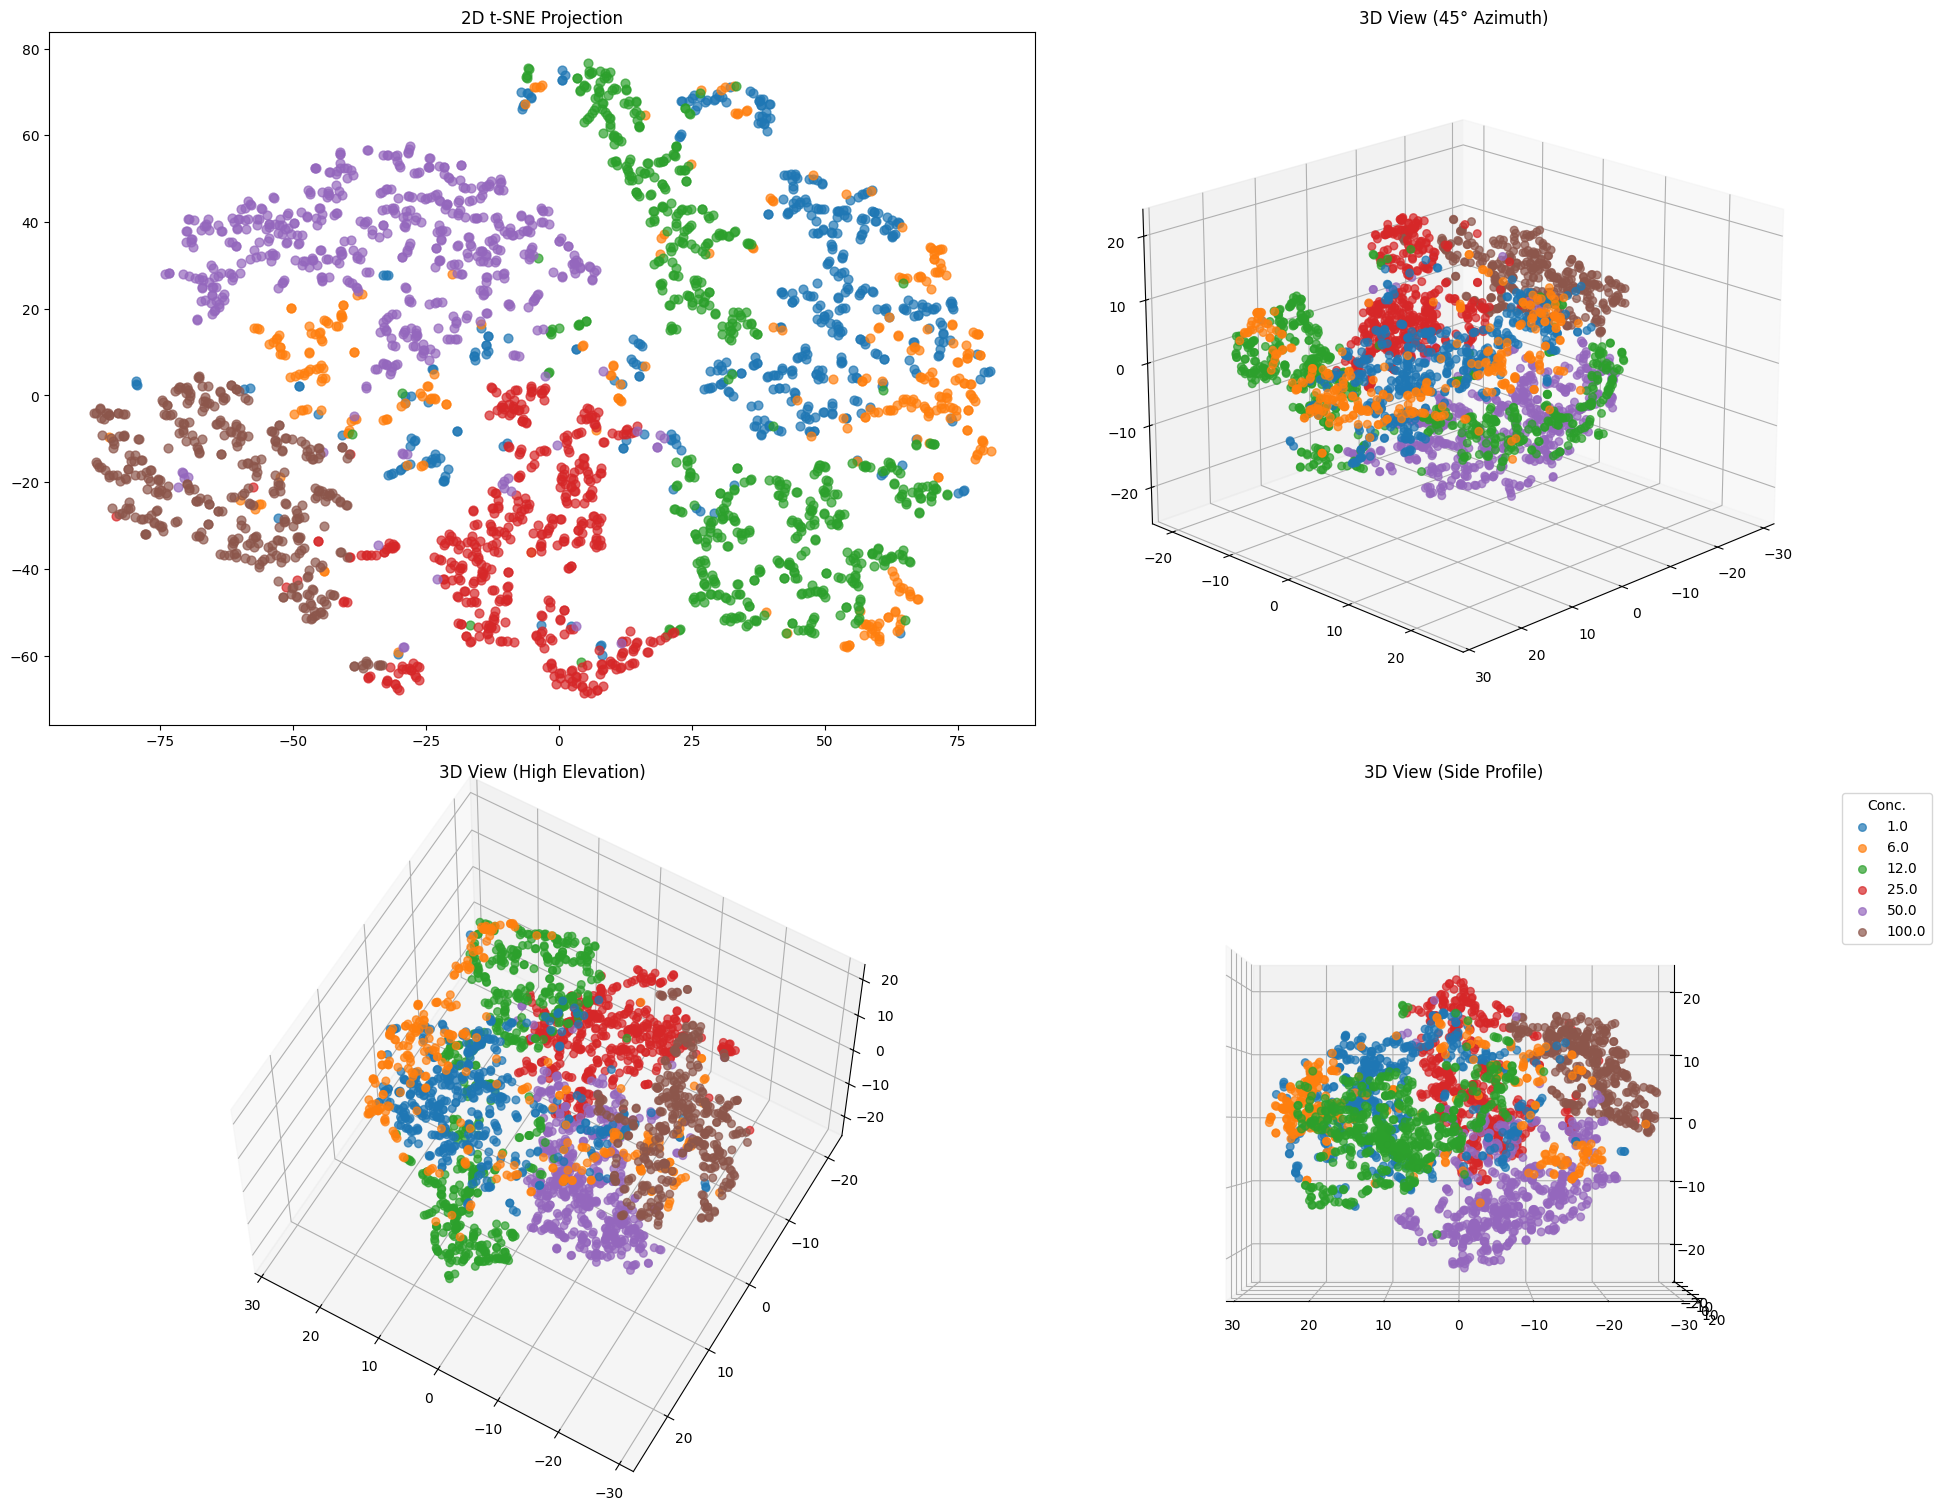

In [8]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import seaborn as sns

# --- 1. Run t-SNE for both 2D and 3D ---
tsne_2d = TSNE(n_components=2, perplexity=10, random_state=42, init='pca', learning_rate='auto')
X_2d = tsne_2d.fit_transform(X_top_50_scaled)

tsne_3d = TSNE(n_components=3, perplexity=10, random_state=42, init='pca', learning_rate='auto')
X_3d = tsne_3d.fit_transform(X_top_50_scaled)

# --- 2. Setup Plotting Layout ---
fig = plt.figure(figsize=(20, 15))
categories = sorted(y.unique(), key=lambda x: float(x))
colors = sns.color_palette("tab10", len(categories))
color_map = dict(zip(categories, colors))

# Helper function to plot on specific axes
def plot_data(ax, data, is_3d=True):
    for label in categories:
        mask = y == label
        if is_3d:
            ax.scatter(data[mask, 0], data[mask, 1], data[mask, 2], 
                       label=label, s=30, alpha=0.7, color=color_map[label])
        else:
            ax.scatter(data[mask, 0], data[mask, 1], 
                       label=label, s=40, alpha=0.7, color=color_map[label])

# View 1: 2D Projection
ax1 = fig.add_subplot(221)
plot_data(ax1, X_2d, is_3d=False)
ax1.set_title("2D t-SNE Projection")

# View 2: 3D Default Angle
ax2 = fig.add_subplot(222, projection='3d')
plot_data(ax2, X_3d)
ax2.view_init(elev=20, azim=45) # Default perspective
ax2.set_title("3D View (45° Azimuth)")

# View 3: 3D Top-Downish
ax3 = fig.add_subplot(223, projection='3d')
plot_data(ax3, X_3d)
ax3.view_init(elev=60, azim=120) 
ax3.set_title("3D View (High Elevation)")

# View 4: 3D Side Profile
ax4 = fig.add_subplot(224, projection='3d')
plot_data(ax4, X_3d)
ax4.view_init(elev=0, azim=90)
ax4.set_title("3D View (Side Profile)")

plt.legend(title="Conc.", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

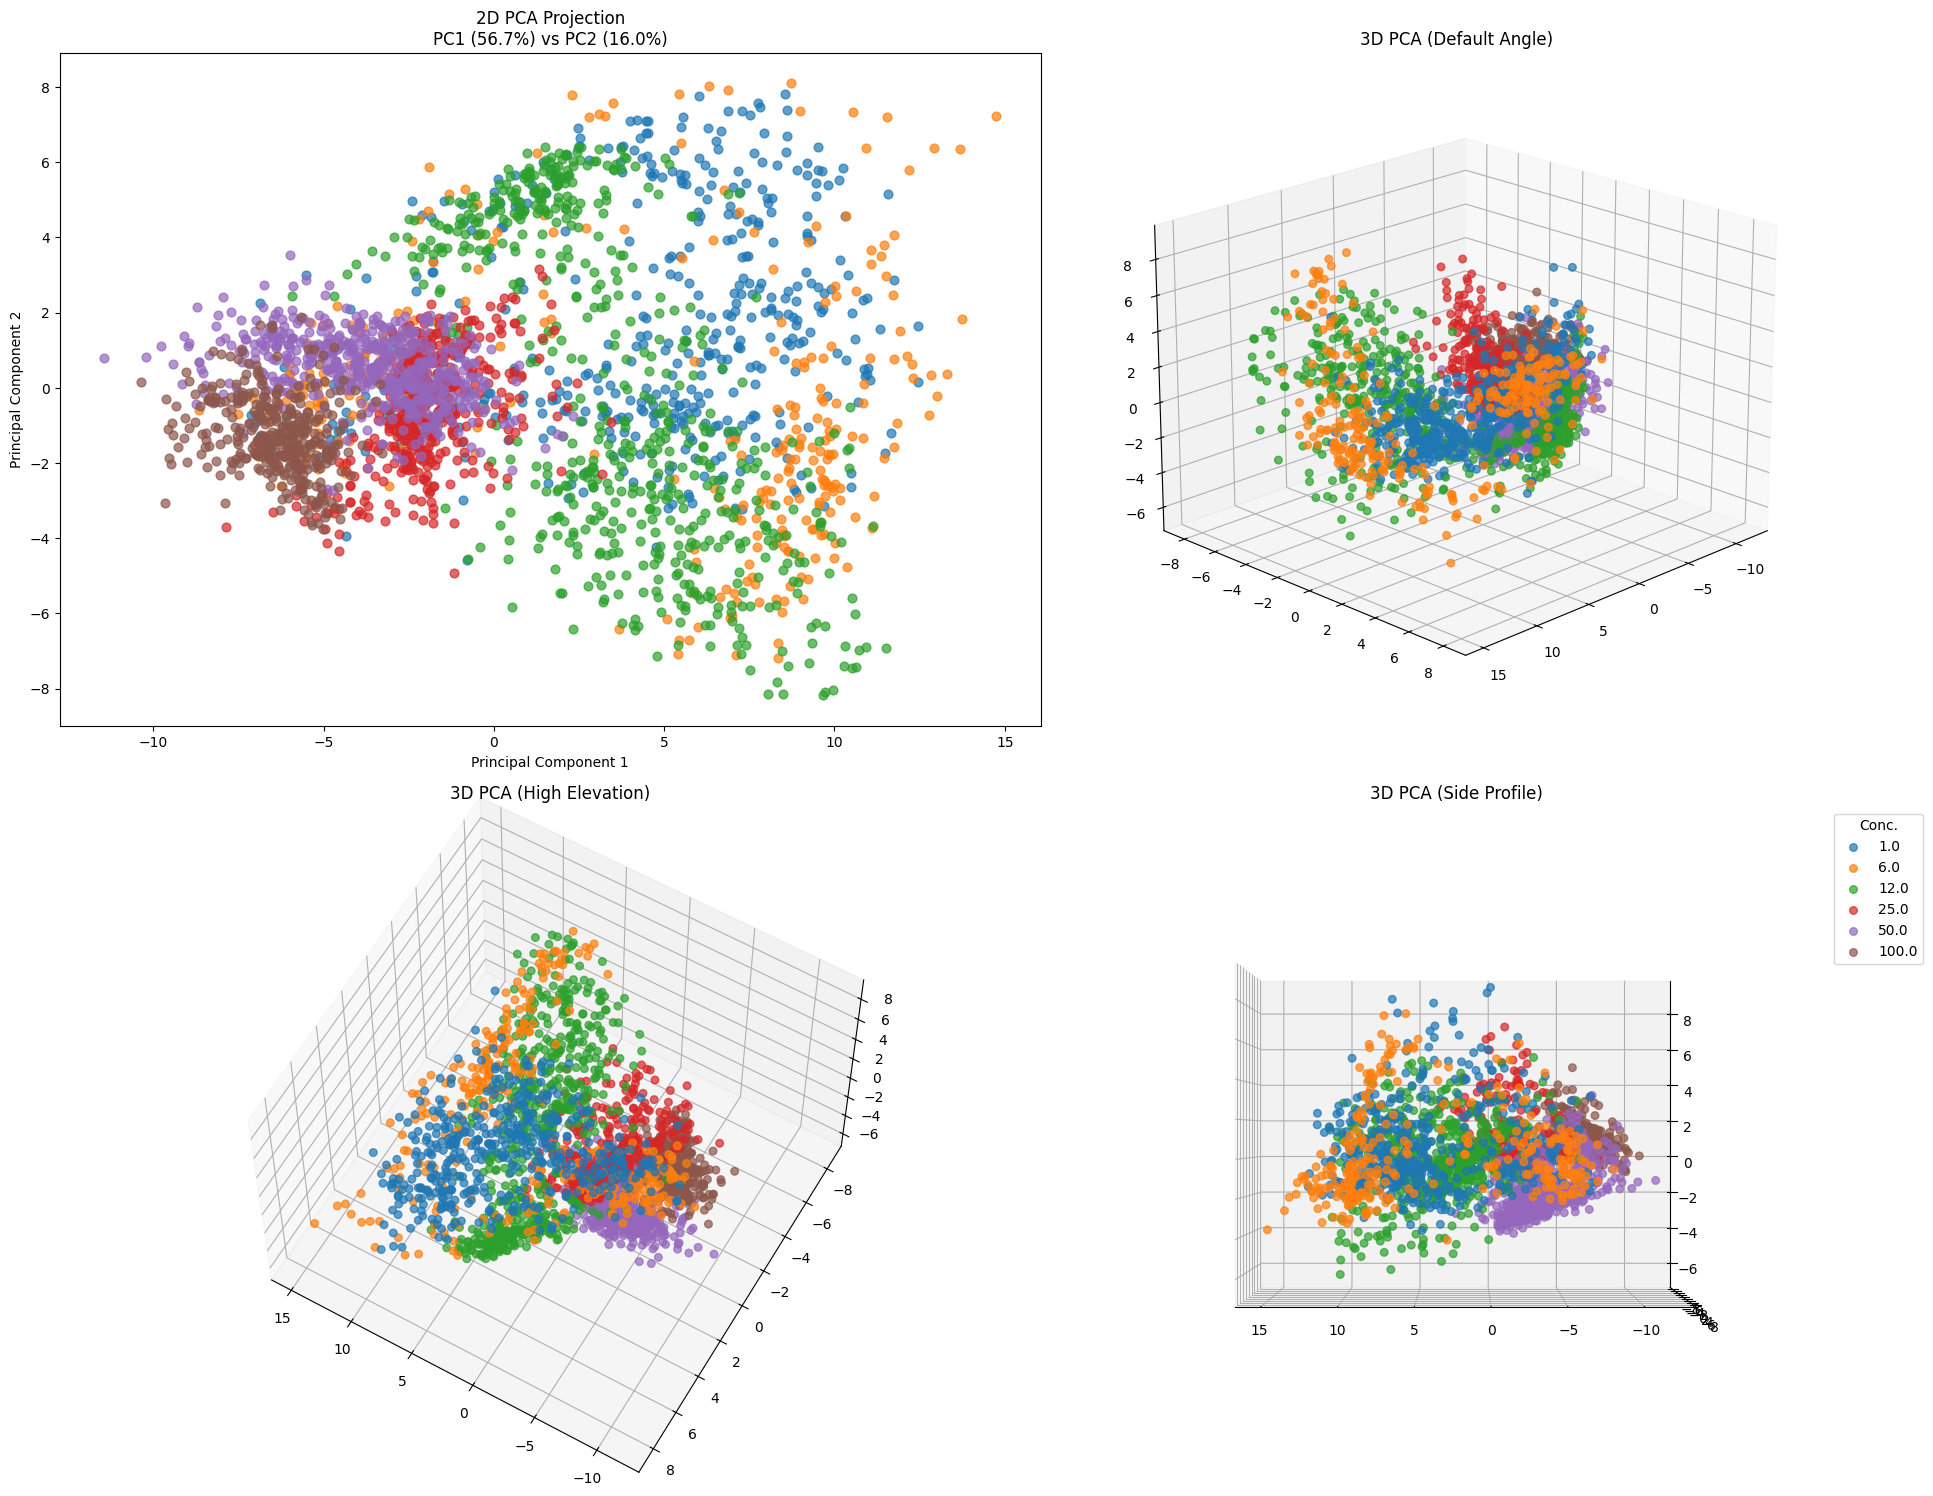

Total variance explained by 3 components: 80.69%


In [9]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import seaborn as sns

# --- 1. Run PCA for both 2D and 3D ---
# We fit the 3D version first, then we can just use the first 2 columns for the 2D plot
pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_top_50_scaled)

# The variance explained tells you how much "information" was captured
explained_var = pca_3d.explained_variance_ratio_ * 100

# --- 2. Setup Plotting Layout ---
fig = plt.figure(figsize=(20, 15))
categories = sorted(y.unique(), key=lambda x: float(x))
colors = sns.color_palette("tab10", len(categories)) # Viridis is great for sequential concentrations
color_map = dict(zip(categories, colors))

# Helper function to plot on specific axes
def plot_pca_data(ax, data, is_3d=True):
    for label in categories:
        mask = y == label
        if is_3d:
            ax.scatter(data[mask, 0], data[mask, 1], data[mask, 2], 
                       label=label, s=30, alpha=0.7, color=color_map[label])
        else:
            ax.scatter(data[mask, 0], data[mask, 1], 
                       label=label, s=40, alpha=0.7, color=color_map[label])

# View 1: 2D Projection (PC1 vs PC2)
ax1 = fig.add_subplot(221)
plot_pca_data(ax1, X_pca_3d[:, :2], is_3d=False)
ax1.set_title(f"2D PCA Projection\nPC1 ({explained_var[0]:.1f}%) vs PC2 ({explained_var[1]:.1f}%)")
ax1.set_xlabel("Principal Component 1")
ax1.set_ylabel("Principal Component 2")

# View 2: 3D Default Angle
ax2 = fig.add_subplot(222, projection='3d')
plot_pca_data(ax2, X_pca_3d)
ax2.view_init(elev=20, azim=45)
ax2.set_title("3D PCA (Default Angle)")

# View 3: 3D High Elevation
ax3 = fig.add_subplot(223, projection='3d')
plot_pca_data(ax3, X_pca_3d)
ax3.view_init(elev=60, azim=120) 
ax3.set_title("3D PCA (High Elevation)")

# View 4: 3D Side Profile
ax4 = fig.add_subplot(224, projection='3d')
plot_pca_data(ax4, X_pca_3d)
ax4.view_init(elev=0, azim=90)
ax4.set_title("3D PCA (Side Profile)")

plt.legend(title="Conc.", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Print the variance breakdown
print(f"Total variance explained by 3 components: {sum(explained_var):.2f}%")

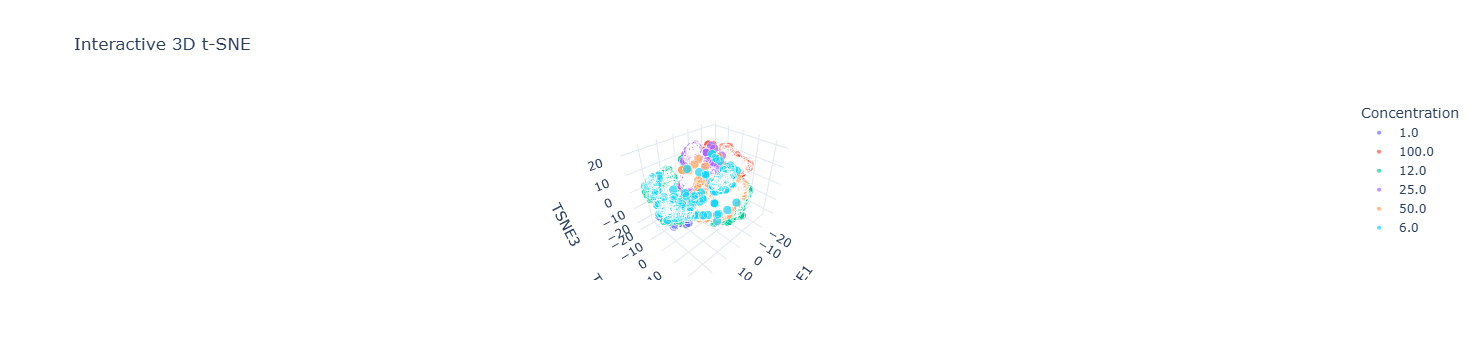

In [10]:
import plotly.express as px

# Create a DataFrame for Plotly
df_3d = pd.DataFrame(X_3d, columns=['TSNE1', 'TSNE2', 'TSNE3'])
df_3d['Concentration'] = y.values

fig = px.scatter_3d(df_3d, x='TSNE1', y='TSNE2', z='TSNE3',
                    color='Concentration',
                    title='Interactive 3D t-SNE',
                    opacity=0.7,
                    template='plotly_white')

# This makes the markers look cleaner
fig.update_traces(marker=dict(size=5, line=dict(width=1, color='White')))
fig.show()

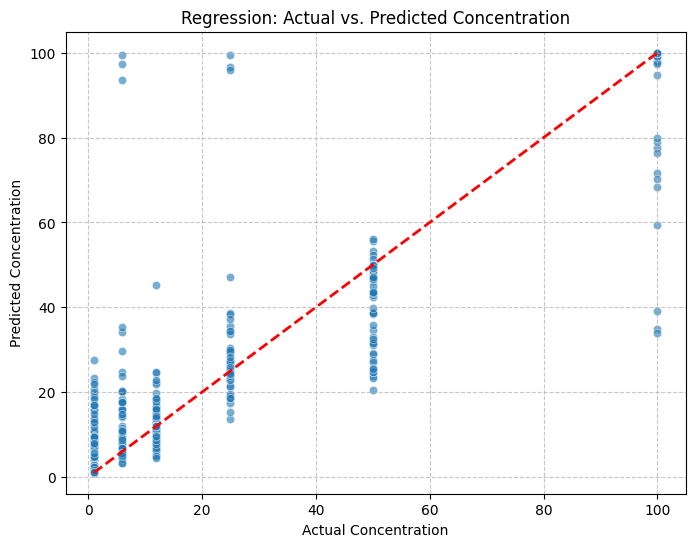


Top 30 Regression Features:
contrast                   0.568888
gabor_ang45_f0.1_mean      0.066110
energy                     0.053112
fft_energy                 0.045989
gabor_ang135_f0.1_mean     0.036895
area_fraction              0.026298
gabor_ang45_f0.3_mean      0.019552
gabor_ang90_f0.3_mean      0.014780
gabor_ang135_f0.3_mean     0.013366
gabor_ang0_f0.3_mean       0.012788
mean_local_std             0.011345
gabor_ang0_f0.1_mean       0.010878
gabor_ang90_f0.1_mean      0.010393
mean_cluster_area          0.009375
skeleton_endpoints         0.008429
edge_density               0.008229
gabor_ang90_f0.3_skew      0.006759
skew                       0.006372
kurtosis                   0.004961
mean_intensity             0.004784
gabor_ang0_f0.3_skew       0.004284
correlation                0.003959
gabor_ang0_f0.1_max        0.003754
gabor_ang135_f0.3_skew     0.003230
gabor_ang90_f0.1_skew      0.002954
std_intensity              0.002504
gabor_ang135_f0.1_skew     0.002395

In [11]:
# 4. VISUALIZATION: Actual vs. Predicted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_reg, y=reg_predictions, alpha=0.6)
plt.plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()],
    "r--",
    lw=2,
)
plt.title("Regression: Actual vs. Predicted Concentration")
plt.xlabel("Actual Concentration")
plt.ylabel("Predicted Concentration")
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

# 5. FEATURE IMPORTANCE (Regression-specific)
reg_importances = pd.Series(reg_model.feature_importances_, index=X.columns)
print("\nTop 30 Regression Features:")
print(reg_importances.sort_values(ascending=False).head(30))

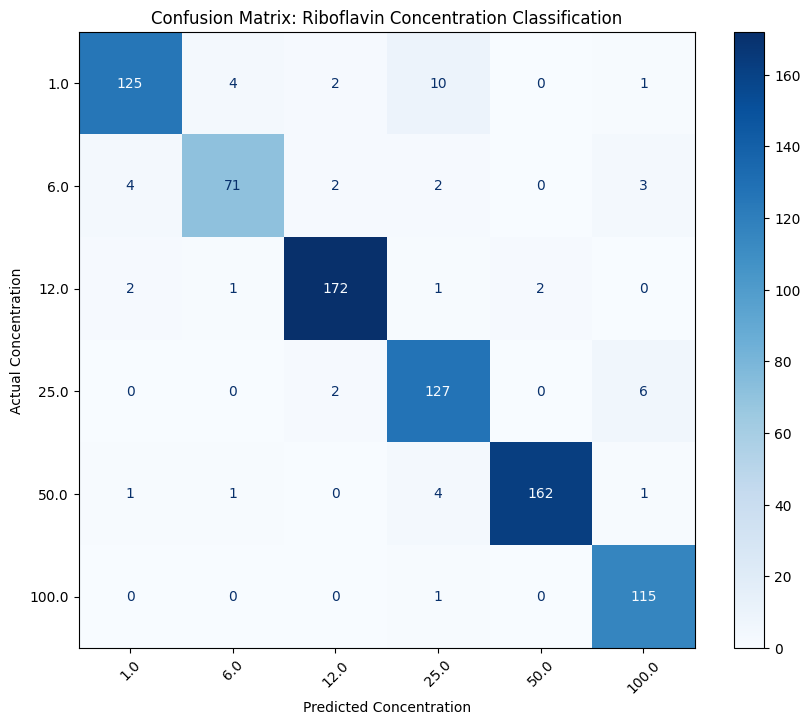

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Get the unique labels and sort them numerically for a clean plot
unique_labels = sorted(y_test.unique(), key=lambda x: float(x))

# 2. Generate the confusion matrix
cm = confusion_matrix(y_test, predictions, labels=unique_labels)

# 3. Create the display
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_labels)

# 4. Plot with a nice color map (Blues or Viridis work well)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)

plt.title('Confusion Matrix: Riboflavin Concentration Classification')
plt.xlabel('Predicted Concentration')
plt.ylabel('Actual Concentration')
plt.show()

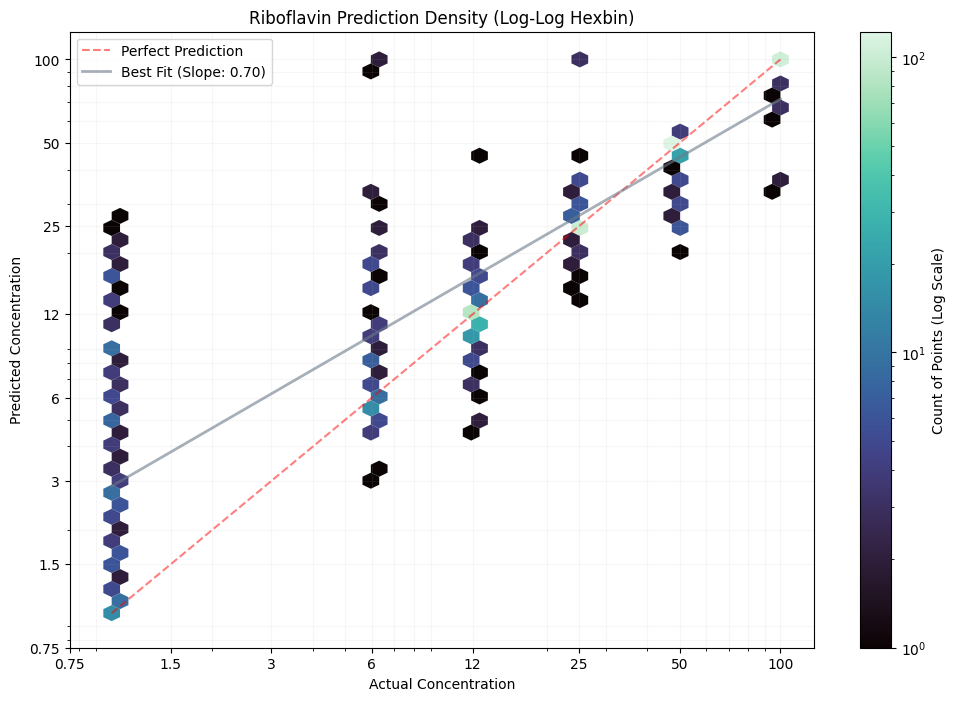

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

# 1. Ensure all values are positive (Log scale requirement)
actual_clean = np.maximum(y_test.astype(float), 1e-5)
predicted_clean = np.maximum(reg_predictions, 1e-5)

# Calculate Best Fit Line in Log-Log Space
slope, intercept = np.polyfit(np.log10(actual_clean), np.log10(predicted_clean), 1)
x_fit = np.logspace(np.log10(actual_clean.min()), np.log10(actual_clean.max()), 100)
y_fit = 10**(slope * np.log10(x_fit) + intercept)

plt.figure(figsize=(12, 8))

# 2. Use Hexbin with logarithmic color scaling
hb = plt.hexbin(
    actual_clean, 
    predicted_clean, 
    gridsize=40, 
    norm=LogNorm(), 
    cmap='mako', 
    xscale='log', 
    yscale='log',
    mincnt=1,
    edgecolors='none'
)

# 3. Add Colorbar
cb = plt.colorbar(hb)
cb.set_label('Count of Points (Log Scale)')

# 4. Perfect Prediction Line (Kept dashed, but softened slightly)
max_val = max(actual_clean.max(), predicted_clean.max())
min_val = min(actual_clean.min(), predicted_clean.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', alpha=0.5, label='Perfect Prediction')

# --- UPDATED: Softer, Solid Best Fit Line ---
plt.plot(x_fit, y_fit, color='#6C7A89', linestyle='-', linewidth=2, alpha=0.6,
         label=f'Best Fit (Slope: {slope:.2f})')
# --------------------------------------------

# 5. Formatting
ticks = [0.75, 1.5, 3, 6, 12, 25, 50, 100]
plt.xticks(ticks, ticks)
plt.yticks(ticks, ticks)

plt.title('Riboflavin Prediction Density (Log-Log Hexbin)')
plt.xlabel('Actual Concentration')
plt.ylabel('Predicted Concentration')
plt.grid(True, which="both", ls="-", alpha=0.1)
plt.legend()

plt.show()

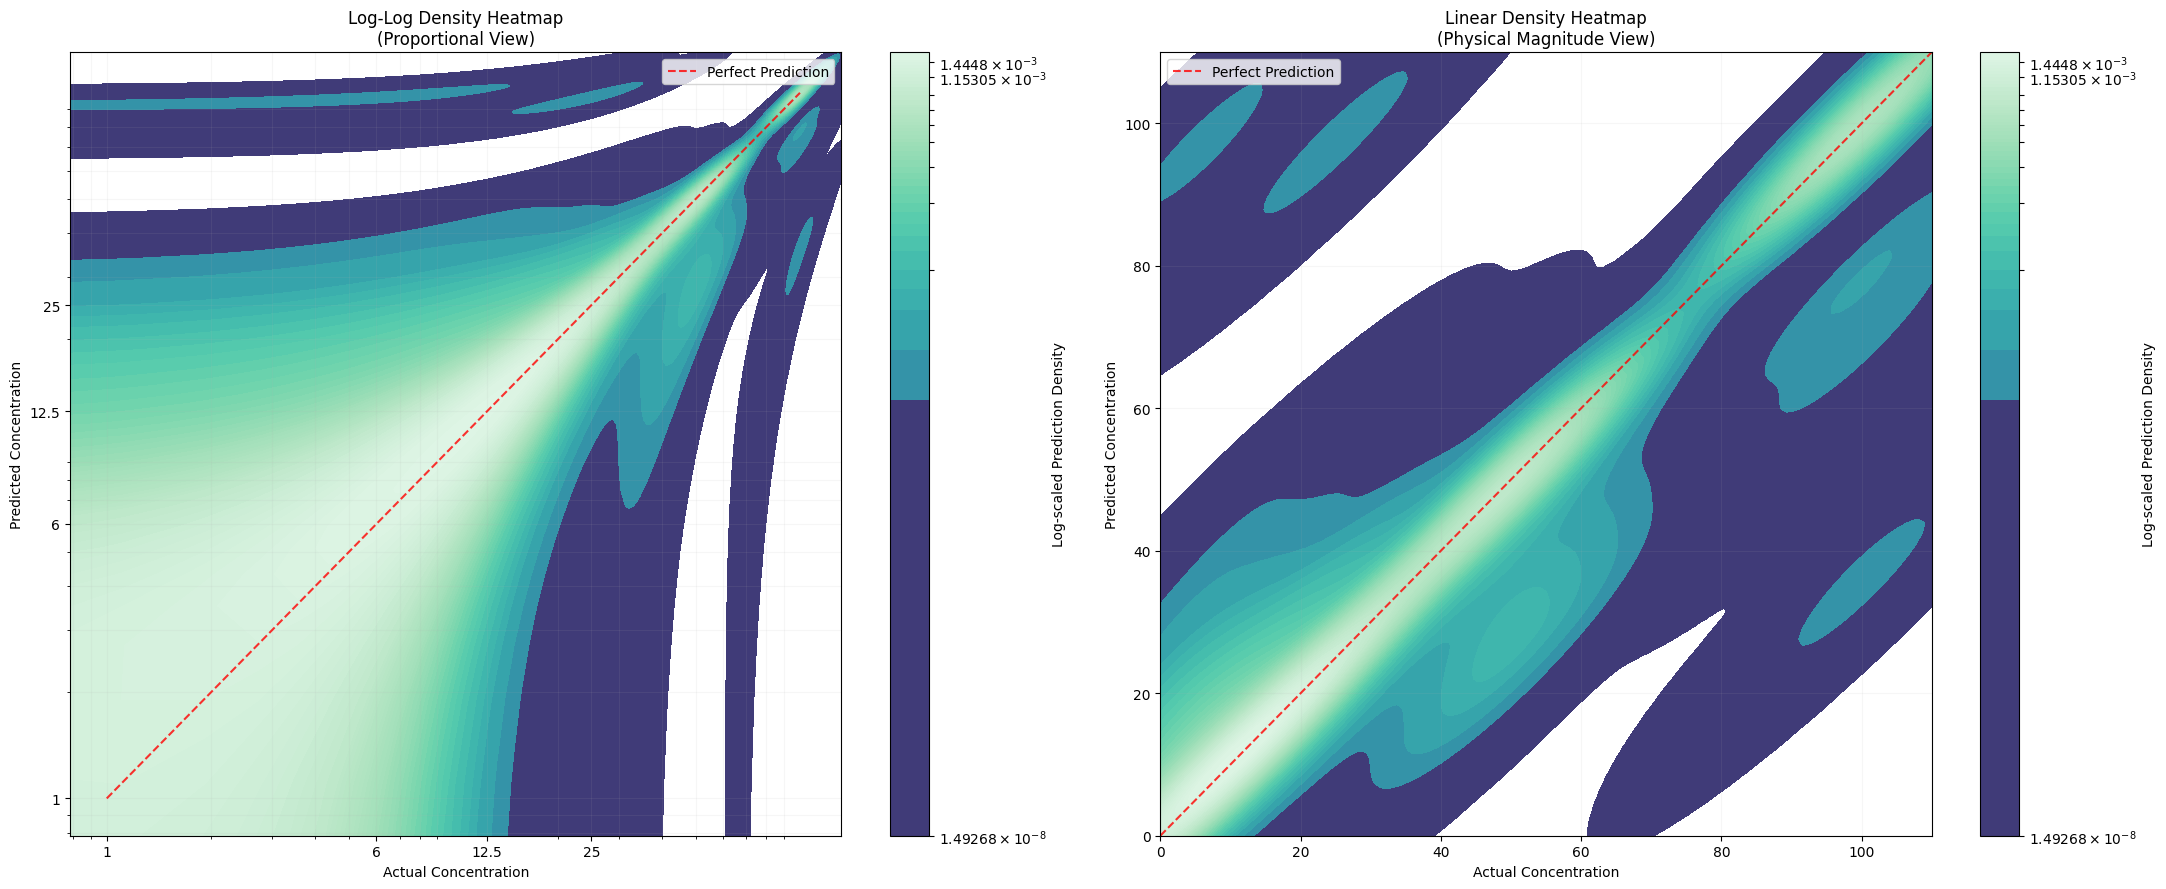

In [14]:
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare data
actual_f = y_test.astype(float)
predicted_f = reg_predictions

# Create the side-by-side figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9))

# Standard ticks for your concentration steps
ticks = [1, 6, 12.5, 25]

# --- LEFT PLOT: YOUR EXACT LOG-LOG CODE ---
sns.kdeplot(
    x=actual_f, y=predicted_f, 
    fill=True, 
    thresh=1e-5, 
    levels=50, 
    norm=LogNorm(), 
    cmap="mako", 
    cbar=True,
    ax=ax1,
    cbar_kws={'label': 'Log-scaled Prediction Density'}
)
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xticks(ticks)
ax1.set_xticklabels(ticks)
ax1.set_yticks(ticks)
ax1.set_yticklabels(ticks)

# Perfect Prediction Line for Log
max_val_log = max(actual_f.max(), predicted_f.max())
min_val_log = min(actual_f.min(), predicted_f.min())
ax1.plot([min_val_log, max_val_log], [min_val_log, max_val_log], color='red', linestyle='--', alpha=0.8, label='Perfect Prediction')

ax1.set_title('Log-Log Density Heatmap\n(Proportional View)')
ax1.set_xlabel('Actual Concentration')
ax1.set_ylabel('Predicted Concentration')
ax1.grid(True, which="both", ls="-", alpha=0.1)
ax1.legend()


# --- RIGHT PLOT: LINEAR VERSION (SAME STYLE) ---
sns.kdeplot(
    x=actual_f, y=predicted_f, 
    fill=True, 
    thresh=1e-5, 
    levels=50, 
    norm=LogNorm(), 
    cmap="mako", 
    cbar=True,
    ax=ax2,
    cbar_kws={'label': 'Log-scaled Prediction Density'}
)

# Perfect Prediction Line for Linear (0 to max)
ax2.plot([0, 110], [0, 110], color='red', linestyle='--', alpha=0.8, label='Perfect Prediction')

ax2.set_title('Linear Density Heatmap\n(Physical Magnitude View)')
ax2.set_xlabel('Actual Concentration')
ax2.set_ylabel('Predicted Concentration')
ax2.set_xlim(0, 110)
ax2.set_ylim(0, 110)
ax2.grid(True, alpha=0.1)
ax2.legend()

plt.tight_layout()
plt.show()